Epoch 1/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.7729 - loss: 1.3990 - val_accuracy: 0.8680 - val_loss: 0.4205
Epoch 2/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8858 - loss: 0.3886 - val_accuracy: 0.8540 - val_loss: 0.4739
Epoch 3/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9149 - loss: 0.2803 - val_accuracy: 0.9150 - val_loss: 0.2944
Epoch 4/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9266 - loss: 0.2207 - val_accuracy: 0.8970 - val_loss: 0.3552
Epoch 5/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9393 - loss: 0.1871 - val_accuracy: 0.9060 - val_loss: 0.3184
Epoch 1/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 141s 964ms/step - accuracy: 0.6257 - loss: 2.1137 - val_accuracy: 0.8550 - val_loss: 0.4612
Epoch 2/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 137s 929ms/step - accuracy: 0.9013 - loss: 0.3162 - val_accuracy: 0.9220 - val_loss: 0.2528
Epoch 3/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 142s 926ms/step - accuracy: 0.9479 - loss: 0.1735 - val_accu

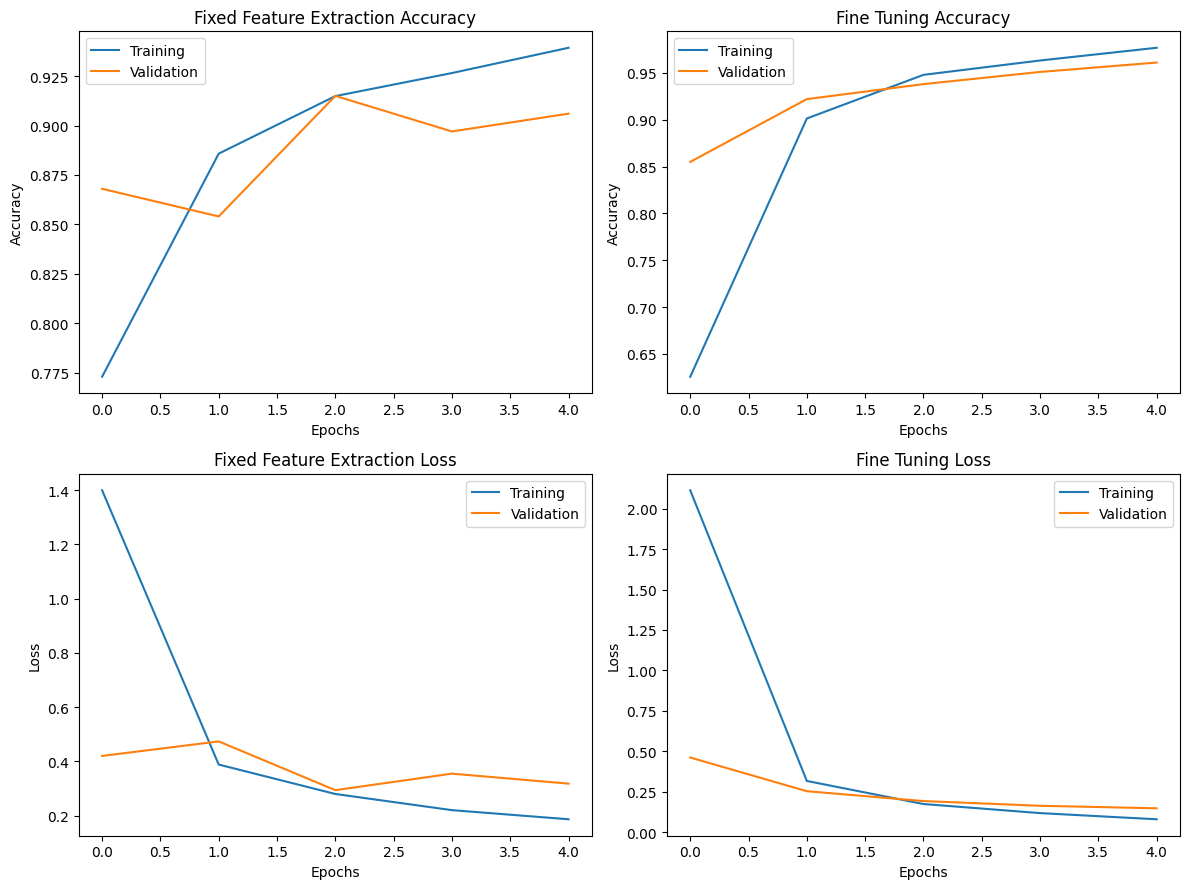

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Flatten, Dense
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train, y_train = x_train[:10000], y_train[:10000]
x_test, y_test = x_test[:2000], y_test[:2000]

# Preprocessing
def prepare(x):
    x = tf.image.resize(x[..., None], (32, 32))
    x = tf.image.grayscale_to_rgb(x)
    return preprocess_input(x.numpy())

x_train = prepare(x_train)
x_test = prepare(x_test)

# One-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Load VGG19
base = VGG19(weights='imagenet', include_top=False,
             input_shape=(32, 32, 3))

# Fixed feature extraction
base.trainable = False

train_features = base.predict(x_train, batch_size=64, verbose=0)
test_features = base.predict(x_test, batch_size=64, verbose=0)

# Classifier
inputs = Input(shape=train_features.shape[1:])
x = Flatten()(inputs)
x = Dense(512, activation='relu')(x)
outputs = Dense(10, activation='softmax')(x)

classifier = Model(inputs, outputs)

classifier.compile(optimizer='adam',
                   loss='categorical_crossentropy',
                   metrics=['accuracy'])

history_fixed = classifier.fit(
    train_features, y_train, epochs=5,
    batch_size=64, validation_split=0.1, verbose=1
)

fixed_loss, fixed_acc = classifier.evaluate(test_features, y_test, verbose=0)

# Fine-tuning - last 4 VGG19 layers
base.trainable = True

for layer in base.layers[:-4]:
    layer.trainable = False

# Build fine-tuning model
inputs = Input(shape=(32, 32, 3))
x = base(inputs)
x = Flatten()(x)
x = Dense(512, activation='relu')(x)
outputs = Dense(10, activation='softmax')(x)

fine_model = Model(inputs, outputs)

fine_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_fine = fine_model.fit(
    x_train, y_train, epochs=5,
    batch_size=64, validation_split=0.1, verbose=1
)

fine_loss, fine_acc = fine_model.evaluate(x_test, y_test, verbose=0)

# Fine-tuning results
print("\nFINE-TUNING RESULTS")
print("Test Accuracy:", round(fine_acc * 100, 2), "%")
print("Test Loss:", round(fine_loss, 4))

# Performance comparison
print("\nPERFORMANCE COMPARISON")
print("Fixed Feature Extraction Accuracy:", round(fixed_acc * 100, 2), "%")
print("Fine Tuning Accuracy:", round(fine_acc * 100, 2), "%")
print("Fixed Feature Extraction Loss:", round(fixed_loss, 4))
print("Fine Tuning Loss:", round(fine_loss, 4))

# Four graphs in one figure
plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.plot(history_fixed.history['accuracy'], label='Training')
plt.plot(history_fixed.history['val_accuracy'], label='Validation')
plt.title('Fixed Feature Extraction Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(history_fine.history['accuracy'], label='Training')
plt.plot(history_fine.history['val_accuracy'], label='Validation')
plt.title('Fine Tuning Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(history_fixed.history['loss'], label='Training')
plt.plot(history_fixed.history['val_loss'], label='Validation')
plt.title('Fixed Feature Extraction Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(history_fine.history['loss'], label='Training')
plt.plot(history_fine.history['val_loss'], label='Validation')
plt.title('Fine Tuning Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()